# Atelier — Préparer des données pour un RAG

**Patrimoine réunionnais · 3 h 30 · Python · tout fonctionne hors ligne**

Trois sources vous attendent : des notices **POP/Mérimée**, des textes **Wikidata/Wikipédia** et des images **Wikimedia Commons**.

**Votre objectif est simple :** rendre ces données faciles à retrouver, sans mélanger des monuments différents et sans perdre la provenance.

À la fin, vous aurez un petit corpus prêt pour un RAG et une réponse argumentée à cette question : **le nettoyage et les images améliorent-ils vraiment la recherche ?**


## Comment travailler ?


Exécutez les cellules dans l’ordre. Si vous êtes deux, réfléchissez à voix haute : l’important est de comprendre **pourquoi** on fait chaque étape.


### Règles simples

- Lisez vos données dans `data/atelier/` et enregistrez vos résultats dans `sorties/`.
- **Ne modifiez jamais `data/brutes/`.**
- En cas de doute sur deux fiches, **ne fusionnez pas au hasard** : marquez le cas « à revoir ».
- **Ne changez plus vos règles** une fois que vous ouvrez les réponses du test final (étape 7).


### Trois images mentales pour tout l’atelier

1. **Un monument (*entité*)** : le vrai bâtiment dans la rue (ex. le musée Léon-Dierx), repéré par son code `qid` (Wikidata) et/ou `ref` (Mérimée).
2. **Une fiche reçue (*observation*)** : une ligne dans un fichier CSV/JSON. Un même monument peut avoir **plusieurs lignes** si une fiche a été copiée deux fois par erreur.
3. **Une photo (*média*)** : une image qui illustre un monument. Une même photo peut parfois montrer deux monuments voisins — ce n’est pas un nouveau monument.


### Votre parcours en un coup d’œil

| Étape | L’idée en une phrase | Fichier produit dans `sorties/` |
|---|---|---|
| **0. Aperçu** | Voir un même monument dans les 3 sources brutes | *(lecture)* |
| **1. État des lieux** | Repérer les défauts des fichiers avant d’y toucher | `diagnostic.csv` |
| **2. Nettoyage du texte** | Rendre les textes propres et comparables sans effacer les accents | *(tests validés)* |
| **3. Enlever les photocopies** | Écarter les lignes copiées en double (empreinte SHA-256) | `decisions_notices.csv`, `decisions_articles.csv` |
| **4. Relier les annuaires** | Faire correspondre chaque fiche Wikipédia à sa notice POP (Levenshtein + Jaccard) | `decisions_liaisons.csv` |
| **5. Trier les photos** | Repérer les doublons visuels et décrire honnêtement 3 images | `candidats_doublons_images.csv` |
| **6. Mettre en fiches RAG** | Découper en morceaux avec leur étiquette d’origine | `documents_rag.jsonl` |
| **7. Mesurer l’effet réel** | Tester le même moteur sur `brut`, `nettoye` et `enrichi` | `evaluation_retrieval.csv`, `resultats_requetes.csv` |
| **8. Bilan** | Expliquer ce que vous avez observé avec vos mots | `compte_rendu.md` |


In [2]:
# Installation des bibliothèques nécessaires (à exécuter une fois)
%pip install -q "numpy>=1.24,<3" "pandas>=2.0,<4" "scikit-learn>=1.3,<2" "Pillow>=10.3,<13" "requests>=2.31,<3" "lxml>=5,<7"


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 0 — Un petit tour sur les sources de données (10 min)


Avant d’ouvrir tout le corpus (étape 1), regardons ce que renvoient **les 3 sources brutes** pour **un seul monument** (enregistré hors ligne dans `data/atelier/exemple_collecte.json`).


Observez trois choses :

1. Les formats sont hétérogènes (champs codés POP `TICO`/`COM`, texte long Wikipédia, métadonnées image Commons).
2. Un identifiant commun (`REF` / `ids_merimee_declares`) permet de relier les sources.
3. Chaque donnée arrive avec sa **provenance** (`url`, `date_collecte`, `licence`).


In [6]:
import json
from pathlib import Path

exemple = json.loads(Path('data/atelier/exemple_collecte.json').read_text(encoding='utf-8'))
pop = exemple['source_1_pop'][0]
wiki = exemple['source_2_wikidata_wikipedia']
img = exemple['source_3_commons'][0]

print('=== 1. POP / Mérimée (extrait brut) ===')
print(json.dumps({
    'source_id': pop['source_id'],
    'url': pop['url'],
    'date_collecte': pop['date_collecte'],
    'notice_brute': {k: pop['notice'].get(k) for k in ['REF', 'TICO', 'COM', 'SCLE', 'POP_COORDONNEES']},
}, ensure_ascii=False, indent=2))

print('\n=== 2. Wikidata / Wikipédia (extrait brut) ===')
print(json.dumps({
    'qid': wiki['source_id'],
    'ids_merimee_declares': wiki['ids_merimee_declares'],
    'titre_wikipedia': wiki['titre_wikipedia'],
    'url_wikipedia': wiki['url_wikipedia'],
    'debut_texte': wiki['texte_integral'][:220].replace('\n', ' ') + '…',
    'taille_texte': len(wiki['texte_integral']),
}, ensure_ascii=False, indent=2))

print('\n=== 3. Wikimedia Commons (métadonnées image) ===')
print(json.dumps({
    'titre_fichier': img['titre_fichier'],
    'auteur': img['auteur'],
    'licence': img['licence'],
    'url_page_description': img['url_page_description'],
    'date_collecte': img['date_collecte'],
}, ensure_ascii=False, indent=2))


=== 1. POP / Mérimée (extrait brut) ===
{
  "source_id": "ACR0001729",
  "url": "https://pop.culture.gouv.fr/notice/merimee/ACR0001729",
  "date_collecte": "2026-11-20T16:24:23+00:00",
  "notice_brute": {
    "REF": "ACR0001729",
    "TICO": "Musée Léon-Dierx",
    "COM": [
      "Saint-Denis"
    ],
    "SCLE": [
      "20e siècle"
    ],
    "POP_COORDONNEES": {
      "lat": -20.8836152538155,
      "lon": 55.4501645123237
    }
  }
}

=== 2. Wikidata / Wikipédia (extrait brut) ===
{
  "qid": "Q3329255",
  "ids_merimee_declares": [
    "ACR0001729"
  ],
  "titre_wikipedia": "Musée Léon-Dierx",
  "url_wikipedia": "https://fr.wikipedia.org/wiki/Mus%C3%A9e_L%C3%A9on-Dierx",
  "debut_texte": "Le musée Léon-Dierx est un musée d'art de l'île de La Réunion, département d'outre-mer français dans le sud-ouest de l'océan Indien. Il est situé dans la rue de Paris à Saint-Denis, le chef-lieu.   == Histoire du musée =…",
  "taille_texte": 8212
}

=== 3. Wikimedia Commons (métadonnées image) ===
{

### Pour explorer les données sur Internet (facultatif)


Les fichiers du TP restent disponibles hors ligne. Si vous voulez comparer avec les pages d’origine :

- **POP / Mérimée** : [notice PA00105810](https://pop.culture.gouv.fr/notice/merimee/PA00105810) · [portail POP](https://pop.culture.gouv.fr/) ;
- **Wikidata** : [entité Q3034582](https://www.wikidata.org/wiki/Q3034582) ;
- **Wikipédia** : [article « Domaine de la Confiance »](https://fr.wikipedia.org/wiki/Domaine_de_la_Confiance) ;
- **Wikimedia Commons** : [photographie reliée à cette entité](https://commons.wikimedia.org/wiki/File:All%C3%A9e-chemin%C3%A9e-Domaine-de-la-Confiance.JPG).


Le [service SPARQL](https://query.wikidata.org/) est aussi accessible en ligne si vous voulez tester une requête Wikidata.


## 1 — Faire connaissance avec les données (25 min)


**L’idée :** avant de réparer une voiture, on ouvre le capot. Ici, vous ouvrez les 3 fichiers de `data/atelier/` pour voir à quoi ils ressemblent et quels défauts ils contiennent :

- `notices` (`source_1_notices.csv`) : fiches officielles POP/Mérimée ;
- `articles` (`source_2_articles.jsonl`) : fiches Wikidata + textes Wikipédia ;
- `images` (`source_3_images.csv`) : informations de chaque photo Commons.


### Ce que vous devez faire

1. Exécutez les deux cellules ci-dessous et **lisez les chiffres affichés** (remarquez que le nombre de lignes est supérieur au nombre de monuments distincts).
2. Choisissez **au moins 3 problèmes concrets** (lignes en double, communes comme `Port (Le)`, `id_merimee` manquants, notice indisponible, champs vides…).
3. Notez-les dans la liste `diagnostic`, puis ré-exécutez pour générer `sorties/diagnostic.csv`.


### Comment savoir que c’est réussi ?

Le tableau final contient au moins 3 lignes claires, avec un **vrai exemple tiré des données** et une phrase expliquant **en quoi cela peut gêner un moteur de recherche**.

<img src="illustrations_etapes/01_profilage_sources.png" alt="Cartes comparant 267 références POP, 247 entités Wikidata et 196 images Commons" style="display:block; max-width:760px; max-height:420px; width:auto; height:auto; margin:18px 0 8px 0; border-radius:8px" />

<small>Compteurs calculés depuis les trois sources du corpus · <a href="ILLUSTRATIONS_SOURCES.md">crédits et licences</a></small>


In [12]:
from pathlib import Path
import json
import hashlib
import re
import unicodedata
import pandas as pd
import numpy as np
from src.aide_etudiant import (
    lire_jsonl, ecrire_jsonl, hachage_fichier, phash_hex,
    distance_hamming_hex, MoteurTfidf, evaluer_recherche,
    documents_depuis_vues, metriques_paires, valider_export_minimal,
)

RACINE = Path.cwd()
ATELIER = RACINE / 'data' / 'atelier'
SORTIES = RACINE / 'sorties'
SORTIES.mkdir(exist_ok=True)

notices = pd.read_csv(ATELIER / 'source_1_notices.csv', keep_default_na=False)
articles = lire_jsonl(ATELIER / 'source_2_articles.jsonl')
images = pd.read_csv(ATELIER / 'source_3_images.csv', keep_default_na=False)

print('Notices POP     :', notices.shape, '| références distinctes (ref) :', notices['ref'].nunique())
print('Articles Wiki   :', len(articles), '| entités distinctes (qid)    :', len({x['qid'] for x in articles}))
print('Images Commons  :', images.shape, '| fichiers distincts (image_id):', images['image_id'].nunique())
print('Notices avec collecte indisponible :', (notices.get('statut_collecte', '') == 'indisponible').sum())
print('\nClés d’un article (source_2) :', list(articles[0].keys()))
print('Colonnes images (source_3)   :', list(images.columns))

display(notices.head(2))


Notices POP     : (273, 20) | références distinctes (ref) : 267
Articles Wiki   : 255 | entités distinctes (qid)    : 247
Images Commons  : (206, 22) | fichiers distincts (image_id): 204
Notices avec collecte indisponible : 1

Clés d’un article (source_2) : ['observation_id', 'qid', 'id_merimee', 'titre_wikipedia', 'label_wikidata', 'description_wikidata', 'alias_fr', 'alias_en', 'texte_integral', 'url_wikidata', 'url_wikipedia', 'coordonnees_wikidata', 'date_collecte']
Colonnes images (source_3)   : ['source', 'image_id', 'qid', 'titre_fichier', 'chemin_local', 'url_page_description', 'url_original', 'url_vignette', 'largeur', 'hauteur', 'taille_octets_originale', 'mime_original', 'sha1_commons_original', 'description_commons', 'auteur', 'credit', 'licence', 'licence_url', 'date_fichier', 'categories', 'date_collecte', 'observation_id']


,observation_id,ref,statut_collecte,erreur_collecte,titre,autres_appellations,commune,code_insee,adresse,denomination,description,histoire,datation,protection,date_protection,latitude,longitude,url,date_collecte,mentions_legales
0,pop:ACR0001473:original,ACR0001473,disponible,,Aéroport Roland-Garros,,Sainte-Marie,97418,,ensemble du génie civil ; aérodrome ; aéroport,,,20e siècle,,,,,https://pop.culture.gouv.fr/notice/merimee/ACR...,2026-11-20T16:24:23+00:00,© Ministère de la Culture / Direction des affa...
1,pop:ACR0001652:original,ACR0001652,disponible,,Ensemble Polaris de la Cité des Étoiles,,Port (Le),97407,Vingt-Décembre-1848 (avenue) 471 ; Félix-Tisse...,édifice domestique ; demeure ; immeuble,,,20e siècle,,,-20.926054,55.340892,https://pop.culture.gouv.fr/notice/merimee/ACR...,2026-11-20T16:24:23+00:00,© Ministère de la Culture / Direction des affa...


In [13]:
# Quelques contrôles déjà écrits pour vous montrer ce qui cloche dans les fichiers.
manquants_pop = (notices == '').mean().sort_values(ascending=False).head(12)
print('Taux de cases vides dans POP (0 = toujours rempli, 1 = toujours vide) :\n', manquants_pop)

print('\n--- Anomalies rapides à observer ---')
print('Lignes POP dont la ref apparaît plusieurs fois :', notices['ref'].duplicated(keep=False).sum())
print('Notice POP vide / indisponible                 :', notices.loc[notices['statut_collecte'] == 'indisponible', 'ref'].tolist())
print('Communes écrites avec l’article entre (...)    :', [c for c in sorted(notices['commune'].unique()) if '(' in c])
print('Articles sans lien id_merimee (P380 caché)     :', len({x['qid'] for x in articles if not x['id_merimee']}), 'monuments distincts')
print('Articles reliés à PLUSIEURS notices POP        :', sum(isinstance(x['id_merimee'], list) and len(x['id_merimee']) > 1 for x in articles))
print('Articles Wikipédia vides (sans texte)          :', sum(not x['texte_integral'] for x in articles))
print('Images dont le fichier manque sur le disque    :', sum(not (RACINE / p).is_file() for p in images['chemin_local'] if p))
print('Lignes images partageant le même image_id      :', images['image_id'].duplicated(keep=False).sum())

# TODO : Complétez la liste `diagnostic` avec au moins 3 anomalies concrètes.
# Recopiez ce petit bloc pour chaque anomalie (5 clés exactes) :
# {
#     'source': 'POP/Mérimée',               # 'POP/Mérimée', 'Wikidata/Wikipédia' ou 'Wikimedia Commons'
#     'anomalie': 'Commune avec article inversé',
#     'frequence': '8 communes concernées',
#     'exemple': 'Port (Le), Tampon (Le)',
#     'risque_retrieval': 'Une recherche sur "Le Tampon" risque de mal correspondre à "Tampon (Le)".',
# }
diagnostic = [
    # Ajoutez au moins 3 dictionnaires ici
]

df_diagnostic = pd.DataFrame(
    diagnostic,
    columns=['source', 'anomalie', 'frequence', 'exemple', 'risque_retrieval'],
)
df_diagnostic.to_csv(SORTIES / 'diagnostic.csv', index=False)
print('\nAnomalies enregistrées dans sorties/diagnostic.csv :', len(df_diagnostic))
display(df_diagnostic)


Taux de cases vides dans POP (0 = toujours rempli, 1 = toujours vide) :
 erreur_collecte        0.996337
autres_appellations    0.974359
description            0.919414
histoire               0.446886
adresse                0.267399
protection             0.241758
datation               0.234432
date_protection        0.194139
longitude              0.069597
latitude               0.069597
denomination           0.014652
mentions_legales       0.003663
dtype: float64

--- Anomalies rapides à observer ---
Lignes POP dont la ref apparaît plusieurs fois : 12
Notice POP vide / indisponible                 : ['PA97400163']
Communes écrites avec l’article entre (...)    : ['Avirons (Les)', "Etang-Salé (L')", 'Plaine-des-Palmistes (La)', 'Port (Le)', 'Possession (La)', 'Saint-Denis ; Possession (La)', 'Tampon (Le)', 'Trois-Bassins (Les)']
Articles sans lien id_merimee (P380 caché)     : 32 monuments distincts
Articles reliés à PLUSIEURS notices POP        : 22
Articles Wikipédia vides (sans t

,source,anomalie,frequence,exemple,risque_retrieval


## 2 — Normaliser sans effacer l’information (20 min)


**L’image mentale :** pensez à une **carte d’identité** face à un **moteur de recherche**.

- Pour **afficher** le nom à l’utilisateur, on veut un beau français propre : **`Église Saint-Denis`** (avec majuscule et accent).
- Pour **comparer** deux noms dans un programme, on fabrique à côté une **étiquette simplifiée** : **`eglise saint denis`**. On ne remplace jamais le vrai titre par cette étiquette.


> **Mini-info — Pourquoi Python peut croire que deux « é » sont différents ?**
>
> Sur ordinateur, la lettre `é` peut être stockée de **deux façons invisibles** :
> - **1 bloc** (*forme recollée*, `NFC`) : `é` ;
> - **2 morceaux** (*forme détachée*, `NFKD`) : `e` + un accent flottant `´`.
>
> À l’écran c’est identique, mais en Python `'e\u0301' == 'é'` renvoie `False` !
>
> - **Recoller** (`NFC`) → texte propre pour l’affichage.
> - **Détacher** (`NFKD`) → permet d’enlever facilement les accents pour comparer.

<img src="illustrations_etapes/02_unicode_explique.png" alt="Deux façons d’écrire la lettre é : forme recollée NFC pour l’affichage et forme détachée NFKD pour enlever les accents" style="display:block; max-width:760px; max-height:420px; width:auto; height:auto; margin:18px 0 8px 0; border-radius:8px" />

<small>Schéma pédagogique de l’atelier · <a href="ILLUSTRATIONS_SOURCES.md">crédits et licences</a></small>


### Boîte à outils Python pour cette étape

| Outil | À quoi ça sert (en une phrase) |
|---|---|
| `unicodedata.normalize('NFC', texte)` | Recolle chaque lettre avec son accent |
| `unicodedata.normalize('NFKC', texte)` | Comme NFC + convertit caractères spéciaux en version standard |
| `unicodedata.normalize('NFKD', texte)` | Sépare chaque lettre de son accent |
| `unicodedata.combining(c)` | Renvoie `0` pour une vraie lettre, ≠ 0 pour un accent flottant |
| `texte.casefold()` | Met en minuscules (plus complet que `.lower()`) |
| `re.sub(r'\s+', ' ', texte)` | Remplace plusieurs espaces / retours à la ligne par un seul espace |
| `re.findall(r'[\w]+', texte)` | Récupère uniquement la liste des mots |


### Ce que vous devez faire

1. **`normaliser_affichage(valeur)`** — texte propre pour l’affichage (**garde** majuscules et accents).
2. **`cle_comparaison(valeur)`** — étiquette simplifiée pour comparer deux noms.
3. **`normaliser_commune(valeur)`** — remet l’article devant : `'Tampon (Le)'` → `'Le Tampon'`.
4. Décommentez les tests et faites-les tous passer.


In [ ]:
def normaliser_affichage(valeur):
    """Rend un texte propre pour l'affichage en gardant majuscules et accents.

    Recette :
    1. Si valeur is None -> '' (sinon str(valeur))
    2. Recoller les accents : unicodedata.normalize('NFC', ...)
    3. Remplacer les espaces insécables ('\u00a0', '\u202f') par ' '
    4. Compresser les espaces multiples avec re.sub(r'\s+', ' ', ...) puis .strip()

    Exemples :
        normaliser_affichage('e\u0301glise') -> 'église'
        normaliser_affichage('  Église\u00a0Saint-Denis  ') -> 'Église Saint-Denis'
    """
    raise NotImplementedError('À implémenter')


def cle_comparaison(valeur):
    """Fabrique une étiquette simplifiée (minuscules, sans accents ni tirets) pour comparer deux noms.

    Recette :
    1. Partir du texte propre : unicodedata.normalize('NFKC', normaliser_affichage(valeur)).casefold()
    2. Enlever les accents : décomposer en 'NFKD' puis garder les caractères où not unicodedata.combining(c)
    3. Ne garder que les mots : ' '.join(re.findall(r'[\w]+', ..., flags=re.UNICODE))

    Exemples :
        cle_comparaison('Église\u00a0de la Résurrection') -> 'eglise de la resurrection'
        cle_comparaison('Église\u00a0Saint-Denis') -> 'eglise saint denis'
    """
    raise NotImplementedError('À implémenter')


def normaliser_commune(valeur):
    """Remet l'article entre parenthèses devant le nom de commune, puis nettoie l'affichage.

    Indice : re.fullmatch(r"(.+?)\s*\((Le|La|Les|L')\)", texte, flags=re.IGNORECASE)

    Exemples :
        normaliser_commune('Tampon (Le)') -> 'Le Tampon'
        normaliser_commune('Possession (La)') -> 'La Possession'
    """
    raise NotImplementedError('À implémenter')


# --- Tests à décommenter : tous doivent passer avant d'aller à l'étape 3 ---
# assert normaliser_affichage('e\u0301glise') == 'église'
# assert normaliser_affichage('  Église\u00a0de   la\u202fRésurrection \n ') == 'Église de la Résurrection'
# assert normaliser_affichage(None) == ''
# assert cle_comparaison('Église\u00a0de la Résurrection') == 'eglise de la resurrection'
# assert cle_comparaison('Église\u00a0Saint-Denis') == 'eglise saint denis'
# assert normaliser_commune('Tampon (Le)') == 'Le Tampon'
# assert normaliser_commune('Port (Le)') == 'Le Port'
# assert normaliser_commune('Possession (La)') == 'La Possession'
# assert cle_comparaison(normaliser_commune('Tampon (Le)')) == 'le tampon'
# for x in ['Église', 'e\u0301glise', 'Tampon (Le)', 'œuvre', '']:
#     assert cle_comparaison(cle_comparaison(x)) == cle_comparaison(x)
# print('Tous les tests de l’étape 2 passent !')


## 3 — Enlever les photocopies (20 min)


**L’image mentale :** imaginez un classeur administratif.


Deux situations se ressemblent, mais n’ont **rien à voir** :

1. **Deux photocopies du même dossier** (*copie technique*) : même numéro (`ref` ou `qid`) **et** exactement le même texte une fois les espaces nettoyés → on range la photocopie de côté et on note pourquoi.
2. **Deux personnes qui portent le même nom** (*homonymes*) : deux numéros **différents** qui s’appellent tous les deux `Maison` → ce sont **deux monuments différents**, on ne les fusionne **pas**.


> **Mini-info — Empreinte SHA-256**
>
> `sha256_texte(texte)` calcule l’**empreinte digitale** d’un texte.
>
> - Deux textes **identiques** → **toujours** la même empreinte.
> - Changez **une seule lettre** → l’empreinte change complètement.
>
> C’est l’outil idéal pour repérer les photocopies exactes.
>
> On ne l’utilise **pas** pour comparer des titres proches : ça, c’est l’**étape 4** (Levenshtein + Jaccard).

<img src="illustrations_etapes/03_copie_technique.png" alt="Schéma d’une notice originale et de sa photocopie technique avec la même empreinte SHA-256" style="display:block; max-width:760px; max-height:420px; width:auto; height:auto; margin:18px 0 8px 0; border-radius:8px" />

<small>Schéma pédagogique de l’atelier · <a href="ILLUSTRATIONS_SOURCES.md">crédits et licences</a></small>

<img src="illustrations_etapes/03_homonymes.png" alt="Quatre notices POP différentes qui s’appellent toutes Maison mais ont des adresses distinctes" style="display:block; max-width:760px; max-height:420px; width:auto; height:auto; margin:18px 0 8px 0; border-radius:8px" />

<small>Schéma pédagogique de l’atelier · <a href="ILLUSTRATIONS_SOURCES.md">crédits et licences</a></small>


### Ce que vous devez faire

1. Pour chaque ligne de `notices`, assemblez les colonnes utiles (`titre`, `autres_appellations`, `commune`, `adresse`, `denomination`, `description`, `histoire`, `datation`, `protection` — **surtout pas `observation_id`**), passez le tout dans `normaliser_affichage(...)`, puis calculez `h = sha256_texte(...)`.
2. Décidez :
   - `'indisponible'` si `statut_collecte == 'indisponible'` ou texte vide ;
   - `'copie_technique'` si le couple `(ref, h)` a déjà été vu (noter l’`observation_id` original dans `representant`) ;
   - `'conserver'` sinon.
3. Faites la même chose pour `articles` avec `(qid, h)` sur le contenu normalisé.
4. Exportez les deux journaux dans `sorties/`.
5. **Observation :** affichez quelques notices qui s’appellent `Maison` avec des `ref` différents — ce ne sont pas des photocopies !


### Comment savoir que c’est réussi ?

- `notices_propres` : **266** lignes (sur 273 = 6 copies + 1 indisponible).
- `articles_propres` : **247** éléments (sur 255 = 8 copies).


In [ ]:
def sha256_texte(texte):
    """Renvoie l'empreinte digitale unique (SHA-256) d'un texte."""
    return hashlib.sha256(texte.encode('utf-8')).hexdigest()


# TODO 1 : Dédoublonner `notices` (ne mettez PAS `observation_id` dans le texte haché !)
# Colonnes attendues dans chaque dict de `decisions_notices` :
#   'observation_id', 'ref', 'hash', 'decision', 'motif', 'representant'
# Valeurs de `decision` : 'conserver', 'copie_technique', 'indisponible'
notices_propres = pd.DataFrame()   # Attendu : 266 lignes
decisions_notices = []             # Attendu : 273 lignes (journal complet)

# TODO 2 : Dédoublonner `articles` par (qid, hash du contenu normalisé d'affichage)
# Colonnes attendues dans chaque dict de `decisions_articles` :
#   'observation_id', 'qid', 'hash', 'decision', 'motif', 'representant'
articles_propres = []              # Attendu : 247 éléments
decisions_articles = []            # Attendu : 255 éléments (journal complet)

# TODO 3 : Décommentez une fois vos boucles écrites :
# pd.DataFrame(decisions_notices).to_csv(SORTIES / 'decisions_notices.csv', index=False)
# pd.DataFrame(decisions_articles).to_csv(SORTIES / 'decisions_articles.csv', index=False)
# print('Notices :', len(notices), '->', len(notices_propres))
# print(pd.Series([d['decision'] for d in decisions_notices]).value_counts())
# print('Articles :', len(articles), '->', len(articles_propres))
# print(pd.Series([d['decision'] for d in decisions_articles]).value_counts())

# TODO 4 (observation) : Affichez les notices dont le titre exact est « Maison »
# (des ref différents → des monuments différents, pas des photocopies).
# display(notices_propres.loc[notices_propres['titre'] == 'Maison', ['ref', 'titre', 'commune', 'adresse']])


## 4 — Relier deux carnets d’adresses (25 min)


**L’image mentale :** vous avez deux carnets sur la table — le carnet officiel **POP/Mérimée** (`notices_propres`, numéroté par `ref`) et l’encyclopédie **Wikidata/Wikipédia** (`articles_propres`, numérotée par `qid`).


Votre mission : **relier chaque fiche Wikipédia à sa fiche POP**, sans jamais associer deux monuments différents par erreur.

<img src="illustrations_etapes/04_rapprochement_entites.png" alt="Schéma reliant un carnet POP et un carnet Wikidata via l’identifiant P380 ou les noms et la commune" style="display:block; max-width:760px; max-height:420px; width:auto; height:auto; margin:18px 0 8px 0; border-radius:8px" />

<small>Schéma pédagogique de l’atelier · <a href="ILLUSTRATIONS_SOURCES.md">crédits et licences</a></small>


### Partie A — Deux règles pour comparer des titres courts


Ici (et **seulement** ici), on code deux mesures complémentaires sur des **noms courts** :

<img src="illustrations_etapes/04_levenshtein_jaccard.png" alt="Tableau comparatif Levenshtein versus Jaccard avec exemples de coquilles et de mots inversés" style="display:block; max-width:760px; max-height:420px; width:auto; height:auto; margin:18px 0 8px 0; border-radius:8px" />

<small>Schéma pédagogique de l’atelier · <a href="ILLUSTRATIONS_SOURCES.md">crédits et licences</a></small>


> **Mini-info — Levenshtein**
>
> C’est le **nombre minimum de touches clavier** (ajouter, effacer ou remplacer une lettre) pour transformer un mot en un autre.
>
> - `chat` → `chats` : **1** ajout
> - `dupont` → `dupond` : **1** remplacement
>
> La **similarité** ramène ce chiffre entre `0` (très différents) et `1` (identiques) :
> `1 - distance / max(len(a), len(b))`.


> **Mini-info — Jaccard**
>
> C’est la **part de mots en commun** (sans se soucier de l’ordre) :
> $J(A, B) = \frac{|A \cap B|}{|A \cup B|}$.
>
> - `"Maison Carrère"` vs `"carrere maison"` → $2/2 = 1{,}0$
> - `"Domaine de la Confiance"` vs `"Domaine Carrère"` → $1/5 = 0{,}2$


> **Mini-info — Pourquoi les deux ensemble ?**
>
> - **Levenshtein** pardonne une petite faute (`Four à chaux` / `Four à cahux`), mais rate les mots inversés.
> - **Jaccard** pardonne les inversions (`Maison Carrère` / `Carrère Maison`), mais rate une faute de frappe.
>
> Combiner les deux (ex. `0,55 × Levenshtein + 0,45 × Jaccard`) couvre les deux cas.

<img src="illustrations_etapes/04_marge_candidats.png" alt="Deux cas de marge entre candidats : marge trop faible à revoir et marge nette en automatique" style="display:block; max-width:760px; max-height:420px; width:auto; height:auto; margin:18px 0 8px 0; border-radius:8px" />

<small>Schéma pédagogique de l’atelier · <a href="ILLUSTRATIONS_SOURCES.md">crédits et licences</a></small>


### Partie B — Relier les fiches

1. Codez `levenshtein`, `similarite` et `score_jaccard`, puis faites passer les tests.
2. Codez `proposer_liens(...)` :
   - **Cas 1 — `id_merimee` renseigné** : lien fort via P380 (attention : parfois `str`, parfois `list`, parfois `[]`).
   - **Cas 2 — `id_merimee` vide (32 monuments)** : comparer les noms avec Levenshtein + Jaccard, renforcer avec la commune, calculer la **marge** (`score_1er − score_2e`), décider `automatique` / `a_revoir` / `rejete`.
3. Exportez `sorties/decisions_liaisons.csv` et inspectez 5 à 10 propositions sans P380.


### Comment savoir que c’est réussi ?

Le CSV contient `qid`, `ref`, `methode`, `score_nom`, `score_total`, `marge`, `statut`, `motif` — et les cas douteux sont bien en `a_revoir`.


In [ ]:
# === Partie A : Levenshtein + Jaccard (utiles pour comparer des TITRES courts) ===

def levenshtein(a, b):
    """Nombre minimum d'opérations (ajout, suppression, remplacement) pour passer de `a` à `b`.

    Idée : pour chaque lettre ca de a et cb de b, prendre le minimum entre :
        precedent[j] + 1,                  # supprimer ca
        courant[j - 1] + 1,                # insérer cb
        precedent[j - 1] + (ca != cb),     # garder (0) ou remplacer (1)
    """
    raise NotImplementedError('À implémenter')


def similarite(a, b):
    """Score entre 0 et 1 : 1 - levenshtein(a, b) / max(len(a), len(b)).

    Cas particulier : renvoie 1.0 si `a` et `b` sont toutes les deux vides.
    """
    raise NotImplementedError('À implémenter')


def score_jaccard(a, b):
    """Part de mots en commun entre a et b : |A & B| / |A | B|.

    Recette :
    1. Transformer a et b en ensembles de mots : set(cle_comparaison(a).split())
    2. Si les deux ensembles sont vides -> 1.0 ; si un seul est vide -> 0.0
    3. Sinon -> len(A & B) / len(A | B)
    """
    raise NotImplementedError('À implémenter')


# Décommentez pour valider vos 3 fonctions :
# assert levenshtein('chat', 'chats') == 1
# assert levenshtein('voiture', 'automobile') == 8
# assert levenshtein('dupont', 'dupond') == 1
# assert abs(similarite('chat', 'chats') - 0.8) < 1e-12
# assert similarite('', '') == 1.0
# assert score_jaccard('Maison Carrère', 'carrere maison') == 1.0
# assert score_jaccard('Domaine de la Confiance', 'Domaine Carrère') > 0
# assert score_jaccard('', '') == 1.0
# assert score_jaccard('Maison', '') == 0.0
# print('Tests Levenshtein + Jaccard : OK')


# === Partie B : Relier les carnets ===

def extraire_refs(valeur):
    """Transforme `id_merimee` (texte, liste ou vide) en une simple liste de références."""
    if isinstance(valeur, list):
        return [str(x).strip() for x in valeur if str(x).strip()]
    s = str(valeur or '').strip()
    return [s] if s else []


def proposer_liens(notices_df, articles_json):
    """Relie chaque article (qid) à sa ou ses notices POP (ref), sans forcer les cas douteux.

    Retour attendu : liste de dictionnaires avec au minimum les clés :
        'qid', 'ref', 'methode', 'score_nom', 'score_total', 'marge', 'statut', 'motif'
    Valeurs autorisées pour `statut` : 'automatique', 'a_revoir', 'rejete', 'non_resolu'.
    """
    raise NotImplementedError('À implémenter')


# --- Exécution, export et inspection ---
# liens = proposer_liens(notices_propres, articles_propres)
# df_liens = pd.DataFrame(liens)
# df_liens.to_csv(SORTIES / 'decisions_liaisons.csv', index=False)
# print(df_liens['statut'].value_counts())
# print(df_liens['methode'].value_counts())
# display(df_liens[df_liens['methode'] != 'P380'].sort_values('score_total', ascending=False).head(10))

# --- Évaluation après gel (quand l'enseignant fournit le fichier de référence) ---
# liens_reference = pd.read_csv('liens_reference_p380.csv')
# y_vrai, y_predit = ..., ...
# print(metriques_paires(y_vrai, y_predit))


## 5 — Comparer les images sans lire dans leur nom (20 min)


**L’image mentale :** comment repérer qu’une photo est en double sur votre ordinateur ?


- **`SHA-256`** compare le **fichier exact octet par octet**. Renommer ne trompe pas SHA-256. Réduire ou recompresser change les octets → SHA-256 ne voit plus rien.
- **`pHash`** fait comme quelqu’un qui **plisse les yeux** : même réduite ou recompressée, la même photo garde une distance pHash très proche de `0` (`<= 4`).


> **Mini-info — Deux pièges à éviter**
>
> 1. Variante redondante **pour le même `qid`** → on n’indexe qu’une fois.
> 2. Même `image_id` relié à **deux `qid` différents** → on **garde les deux liens** (une vue large peut montrer deux lieux).
> 3. **Ne décrivez jamais une image à partir de son nom de fichier.**

<img src="illustrations_etapes/05_phash_avant_apres.png" alt="La même propriété avant et après redimensionnement, avec un SHA-256 différent mais une distance pHash nulle" style="display:block; max-width:760px; max-height:420px; width:auto; height:auto; margin:18px 0 8px 0; border-radius:8px" />

<small>Domaine de Clermont, Thierry Caro — CC BY-SA 3.0 ; variante pédagogique réencodée · <a href="ILLUSTRATIONS_SOURCES.md">crédits et licences</a></small>


### Ce que vous devez faire

1. Exécutez la 1re cellule (3 photos + paires suspectes).
2. Vérifiez de vos yeux 2 paires (1 copie exacte, 1 variante recompressée).
3. Construisez `images_pour_index` (repère : **206 → 198**).
4. Remplissez `observations_visuelles` pour les 3 photos observées, puis validez `documents_images`.


image_id=15221872 | qid=Q3034582 | File:Allée-cheminée-Domaine-de-la-Confiance.JPG


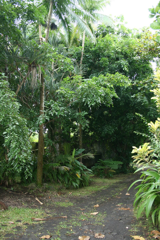

image_id=15096072 | qid=Q2845786 | File:Ancien-génie-militaire.JPG


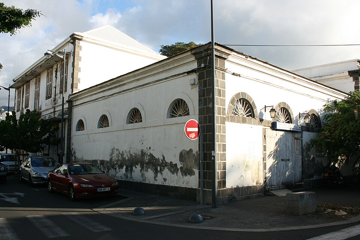

image_id=15104293 | qid=Q2845790 | File:Ancien-hôpital-Félix-Guyon.JPG


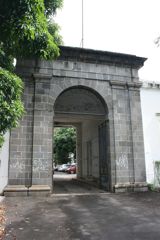

Paires candidates trouvées : 8


,a,b,sha_identique,distance_phash
0,115207332,variante_02,True,0
1,14848334,variante_08,False,0
2,14848717,variante_07,False,0
3,14850837,variante_04,True,0
4,15220978,variante_06,False,0
5,16137073,variante_05,False,0
6,22140976,variante_03,True,0
7,22660545,variante_01,True,0


In [14]:
# 1. Regardez trois vraies photos (notez leur image_id pour la cellule suivante)
from PIL import Image

echantillon = images[images['chemin_local'] != ''].drop_duplicates('image_id').head(3)
for _, ligne in echantillon.iterrows():
    chemin = RACINE / ligne['chemin_local']
    print(f"image_id={ligne['image_id']} | qid={ligne['qid']} | {ligne['titre_fichier']}")
    with Image.open(chemin) as im:
        apercu = im.copy()
    apercu.thumbnail((360, 240))
    display(apercu)

# 2. Calcul SHA-256 (octets) et pHash (apparence) sur chaque fichier distinct
codes = {}
for _, ligne in images.drop_duplicates('image_id').iterrows():
    chemin = RACINE / ligne['chemin_local']
    if chemin.is_file():
        codes[ligne['image_id']] = (str(chemin), hachage_fichier(chemin), phash_hex(chemin))

paires_proches = []
ids = sorted(codes)
for i, a in enumerate(ids):
    for b in ids[i + 1:]:
        sha_a, ph_a = codes[a][1:]
        sha_b, ph_b = codes[b][1:]
        distance = distance_hamming_hex(ph_a, ph_b)
        if sha_a == sha_b or distance <= 4:
            paires_proches.append({'a': a, 'b': b, 'sha_identique': sha_a == sha_b, 'distance_phash': distance})

df_paires_images = pd.DataFrame(paires_proches)
df_paires_images.to_csv(SORTIES / 'candidats_doublons_images.csv', index=False)
print('Paires candidates trouvées :', len(df_paires_images))
display(df_paires_images)

# TODO 1 : Affichez visuellement 2 paires (1 avec sha_identique=True, 1 avec sha_identique=False).
# Indice : codes[id_img][0] donne le chemin du fichier !

# TODO 2 : Construisez `images_pour_index` en retirant les variantes doublons AU SEIN D'UN MÊME `qid`.
# Repère : 206 lignes -> 198 lignes.
images_pour_index = pd.DataFrame()


In [ ]:
def document_image(ligne, inspection_visuelle=None):
    """Transforme une ligne d'image en fiche RAG traçable (sans rien inventer à partir du nom de fichier)."""
    description = str(ligne.get('description_commons', '')).strip()
    titre = str(ligne.get('titre_fichier', '')).removeprefix('File:')
    if inspection_visuelle:
        texte = f'Observation visuelle validée par les étudiants : {inspection_visuelle}'
        base, valide = 'visuel_humain', True
        mode, synthetique = 'annotation_humaine', False
    elif description:
        texte = f'Description fournie par Wikimedia Commons : {description}'
        base, valide = 'metadonnees', False
        mode, synthetique = 'source_metadonnees', False
    else:
        texte = 'Description visuelle absente : le titre seul ne permet pas d’affirmer ce que montre l’image.'
        base, valide = 'absente', False
        mode, synthetique = 'absence', False
    return {
        'chunk_id': hashlib.sha256(f"{ligne['qid']}|{ligne['image_id']}|{texte}".encode()).hexdigest()[:24],
        'entity_id': ligne['qid'], 'text': texte,
        'source': 'Wikimedia Commons', 'source_id': str(ligne['image_id']),
        'url': ligne['url_page_description'], 'date_collecte': ligne['date_collecte'],
        'licence': ligne['licence'] or 'non renseignée', 'mode_production': mode,
        'est_synthetique': synthetique, 'parents_ids': [],
        'hash_texte': hashlib.sha256(texte.encode('utf-8')).hexdigest(),
        'description_basis': base, 'validation_visuelle': valide,
        'chemin_local': ligne['chemin_local'], 'auteur': ligne['auteur'],
    }


# TODO : Décrivez en une phrase neutre ce que vous voyez réellement sur les 3 photos affichées plus haut.
observations_visuelles = {
    # Exemple : '15221872': 'Cheminée en pierre au bout d’une allée bordée d’arbres.',
}

# Décommentez une fois `images_pour_index` et `observations_visuelles` prêts :
# documents_images = [
#     document_image(ligne, inspection_visuelle=observations_visuelles.get(str(ligne['image_id'])))
#     for _, ligne in images_pour_index.iterrows()
# ]
# assert valider_export_minimal(documents_images)
# print('Fiches images valides :', len(documents_images))
# print(pd.Series([d['description_basis'] for d in documents_images]).value_counts())


## 6 — Ranger les informations pour les retrouver (20 min)


**L’image mentale :** les **fiches bristol d’une bibliothèque**.


Un assistant RAG ne lit pas un livre entier d’un coup : il pioche quelques fiches courtes (*chunks*). Chaque fiche doit contenir :

1. **Un passage d’une seule source** (on ne mélange jamais POP + Wikipédia + Commons sur la même fiche) ;
2. **L’étiquette du monument** (`entity_id`) ;
3. **Son passeport d’origine** : source, `url`, `date_collecte`, `licence`, `mode_production`, `parents_ids`.


La fonction `creer_chunk(...)` est **déjà écrite** ci-dessous.

<img src="illustrations_etapes/06_catalogue_bibliotheque.png" alt="Photographie d’un catalogue de bibliothèque, utilisée comme image mentale du retrieval et de la provenance documentaire" style="display:block; max-width:760px; max-height:420px; width:auto; height:auto; margin:18px 0 8px 0; border-radius:8px" />

<small>US National Archives — domaine public · <a href="ILLUSTRATIONS_SOURCES.md">crédits et licences</a></small>


### Les 5 familles de fiches à mettre dans `documents_rag`

1. **Notices POP/Mérimée** (`mode_production='source'`)
2. **Métadonnées Wikidata** (`mode_production='source_metadonnees'`, licence `'CC0'`)
3. **Articles Wikipédia** (découpés avec `decouper_texte` si > 1400 caractères)
4. **Photos Commons** (`documents_images` de l’étape 5)
5. **Fiche résumé POP** (*projection structurée*) : phrase factuelle construite par règle fixe, avec `parents_ids` pointant vers la notice d’origine


### Comment savoir que c’est réussi ?

`assert valider_export_minimal(documents_rag)` passe et `sorties/documents_rag.jsonl` est créé.


In [ ]:
def decouper_texte(texte, taille_max=1400, recouvrement=120):
    """Découpe un long texte en morceaux d'au plus `taille_max` caractères.

    Idée : avancer par pas de (taille_max - recouvrement) en coupant sur un espace
    (avec `rfind(' ')`) pour ne pas couper un mot en deux.
    """
    texte = normaliser_affichage(texte)
    if not texte:
        return []
    if len(texte) <= taille_max:
        return [texte]
    raise NotImplementedError('À implémenter')


def creer_chunk(entity_id, text, source, source_id, url, date_collecte, licence, mode_production, index=0, parents_ids=None):
    """Outil fourni : fabrique une fiche RAG avec les 12 champs vérifiés par valider_export_minimal."""
    propre = normaliser_affichage(text)
    cle_id = f'{entity_id}|{source}|{source_id}|{index}|{propre}'
    return {
        'chunk_id': 'chk_' + hashlib.sha256(cle_id.encode('utf-8')).hexdigest()[:24],
        'entity_id': str(entity_id),
        'text': propre,
        'source': source,
        'source_id': str(source_id),
        'url': url or '',
        'date_collecte': date_collecte or '',
        'licence': licence or 'non renseignée',
        'mode_production': mode_production,
        'est_synthetique': False,
        'hash_texte': sha256_texte(propre),
        'parents_ids': list(parents_ids or []),
    }


# TODO : Remplissez `documents_rag` avec vos 5 familles de fiches.
documents_rag = []

# Décommentez une fois `documents_rag` rempli :
# assert len(documents_rag) > 0
# assert valider_export_minimal(documents_rag)
# ecrire_jsonl(SORTIES / 'documents_rag.jsonl', documents_rag)
# print('Total fiches valides :', len(documents_rag), '| Monuments distincts :', len({d['entity_id'] for d in documents_rag}))
# print('\nRépartition par source :\n', pd.Series([d['source'] for d in documents_rag]).value_counts())
# print('\nRépartition par mode_production :\n', pd.Series([d['mode_production'] for d in documents_rag]).value_counts())
